<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/statistics/index.html">Statistics</a><span class="sep">·</span>Part 5 · Uncertainty</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">School maths. Python or R for the notebooks.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A p-value is the probability of getting data at least as extreme as yours if the null hypothesis and every assumption of the model are true. It is among the most used numbers in science and among the most misread, and every misreading asks it to answer a question it was never computed to answer. We simulate tens of thousands of two-group experiments to see what a p-value carries and what it does not. With no effect, p-values spread evenly between 0 and 1, so one in twenty lands below 0.05 by construction. In a simulated field where one tested effect in ten is real, 57% of the results with p < 0.05 come from experiments where nothing happened. An effect of 0.02 standard deviations reaches significance in 89% of experiments with 50,000 people per group, while an effect 25 times larger is missed in 82% of experiments with 10. Twenty tests on pure noise give at least one significant result in 64% of studies. Afterwards you should be able to state what a p-value means, recognise the four common misreadings, and say what else you need before believing a significant result.
:::

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# fallcolor is the site's colour module at the repo root, not an installed package.
sys.path.insert(
    0,
    str(
        next(
            p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "fallcolor.py").exists()
        )
    ),
)
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False
warnings.formatwarning = lambda msg, cat, *_, **__: f"{cat.__name__}: {msg}\n"

ALPHA = 0.05
rng = np.random.default_rng(2016)
C = fallcolor.palette.discrete("default")


def experiments(delta, n, reps):
    """p-values and estimated effects from `reps` experiments, n per group, SD 1.

    For normal data the sample mean is normal and the sample variance a scaled
    chi-squared, so we draw those summaries instead of every observation."""
    means = rng.normal(0.0, np.sqrt(1 / n), size=(reps, 2))
    means[:, 1] += delta
    sds = np.sqrt(rng.chisquare(n - 1, size=(reps, 2)) / (n - 1))
    test = stats.ttest_ind_from_stats(
        means[:, 1], sds[:, 1], n, means[:, 0], sds[:, 0], n
    )
    return test.pvalue, means[:, 1] - means[:, 0]

A p-value answers one narrow question: *if nothing were going on, how surprising would data like mine be?* It does not answer the question people usually want answered, which is *how likely is it that something is going on, and how much?* Every misreading below asks the p-value to answer the second question, which it was never computed to answer. The American Statistical Association said so in a formal statement in 2016[^1], and Greenland and colleagues list the misreadings one by one[^2]. Here we watch the main ones happen in simulation.

## What a p-value is

A test starts from a **null hypothesis** $H_0$, usually "no difference" or "no effect", and a **test statistic** that measures how far the data sit from it. The p-value is

$$p = \Pr\left(|T| \ge |t_{\text{obs}}| \;\middle|\; H_0 \text{ and the model}\right)$$

where $t_{\text{obs}}$ is the statistic computed from your data and $T$ is the same statistic as a random quantity, the value it would take across repeated experiments. The vertical bars make it two-sided: a gap in either direction counts. "The model" is everything else the calculation assumes: independent observations, a distribution of the assumed shape, and a test chosen before the data were seen. If any of that fails, the p-value answers a question about a different experiment.

If $p$ falls below a threshold $\alpha$ fixed in advance, conventionally $0.05$, the result is called **statistically significant** and $H_0$ is **rejected**. That is the rule the [Kolmogorov–Smirnov test](../ks_test/ks_test.ipynb) applies to two harvest curves.

Most examples below use the same experiment: two groups of $n$ observations each, drawn from normal distributions with standard deviation 1, the second group's mean higher by a true effect $\delta$. So $\delta$ is in standard-deviation units: $\delta = 0.5$ means the groups differ by half the spread within either. The statistic is the two-sample t-test, the difference in group means divided by its standard error. First, $\delta = 0$, so $H_0$ is true, repeated 20,000 times.

In [2]:
REPS = 20_000
p_null, _ = experiments(0.0, 20, REPS)
print(
    f"no effect, n = 20 per group: {np.mean(p_null < ALPHA):.3f} of p-values below 0.05, "
    f"{np.mean(p_null < 0.01):.3f} below 0.01, {np.mean(p_null > 0.5):.3f} above 0.5"
)

p_real = {n: experiments(0.5, n, REPS)[0] for n in (10, 30, 100)}
for n, p in p_real.items():
    print(
        f"effect 0.5 SD, n = {n:>3} per group: median p = {np.median(p):.4f}, share below 0.05 = {np.mean(p < ALPHA):.2f}"
    )

no effect, n = 20 per group: 0.050 of p-values below 0.05, 0.011 below 0.01, 0.499 above 0.5
effect 0.5 SD, n =  10 per group: median p = 0.2600, share below 0.05 = 0.18
effect 0.5 SD, n =  30 per group: median p = 0.0562, share below 0.05 = 0.48
effect 0.5 SD, n = 100 per group: median p = 0.0005, share below 0.05 = 0.94


With no effect, 5.0% of p-values fall below 0.05, 1.1% below 0.01, and 49.9% above 0.5. The p-values are uniform: every value between 0 and 1 is equally likely, so a share $\alpha$ of experiments falls below $\alpha$. That is the whole content of the 0.05 threshold. It caps the false-positive rate *when $H_0$ is true*, and says nothing about any single result.

Now give the second group a real effect of $\delta = 0.5$ and vary the group size. With 10 per group the median p-value is 0.26 and only 18% of experiments reach significance. With 30 the median is 0.056 and 48% do. With 100 the median is 0.0005 and 94% do. The share that reaches significance is the test's **power**, which the Kolmogorov–Smirnov module's sweep over pruning delay was measuring.

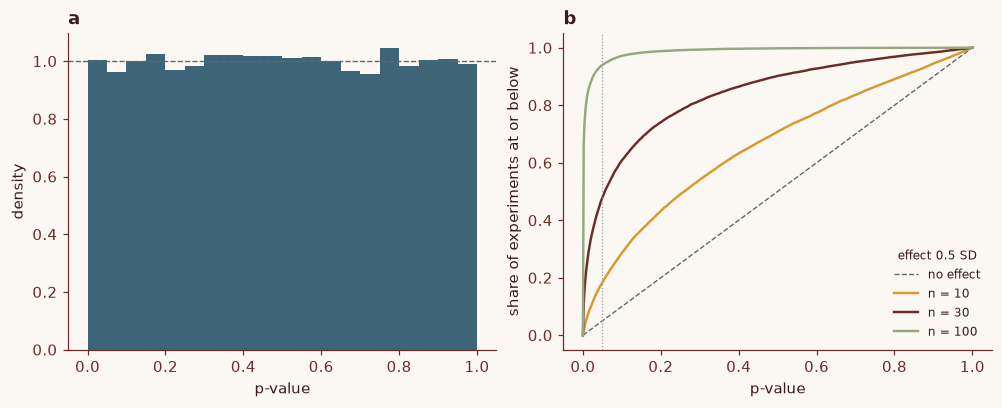

In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
a.hist(p_null, bins=20, range=(0, 1), density=True, color=C[0], alpha=0.85)
a.axhline(1, color="0.4", lw=0.9, ls="--")
a.set_xlabel("p-value")
a.set_ylabel("density")
a.set_title("a", loc="left", fontweight="bold")

grid = np.linspace(0, 1, 501)
b.plot(grid, grid, color="0.4", lw=0.9, ls="--", label="no effect")
for (n, p), c in zip(p_real.items(), C[1:]):
    b.plot(
        grid,
        np.searchsorted(np.sort(p), grid, side="right") / len(p),
        color=c,
        lw=1.6,
        label=f"n = {n}",
    )
b.axvline(ALPHA, color="0.6", lw=0.8, ls=":")
b.set_xlabel("p-value")
b.set_ylabel("share of experiments at or below")
b.legend(
    frameon=False,
    fontsize=8,
    title="effect 0.5 SD",
    title_fontsize=8,
    loc="lower right",
)
b.set_title("b", loc="left", fontweight="bold")
plt.show()

<strong>Figure 1 | With no effect a p-value is uniform; with a real effect, how small it gets depends on the sample size.</strong> <strong>a</strong>, p-values from 20,000 simulated experiments with no true effect, 20 per group; dashed, the uniform density. <strong>b</strong>, Share of experiments at or below each p-value for a true effect of 0.5 standard deviations with 10, 30 or 100 per group; dashed, no effect. Where each curve crosses the dotted line at 0.05 is that design's power.

One effect, three very different p-value distributions. A p-value describes the effect and the sample size together, never the effect alone.

## Not the chance the null is true

A common misreading is that $p = 0.03$ means a 3% chance of no effect. The definition runs the other way: a p-value is a probability of data *given* $H_0$, and the claim is a probability of $H_0$ *given* data. Converting one into the other needs a fact the p-value does not contain: how often the hypotheses being tested are real.

So simulate a field. Each of 20,000 hypotheses is real with some probability, real ones have $\delta = 0.5$, and every experiment has 20 per group. What share of the significant results came from hypotheses with no effect?

In [4]:
HYPOTHESES = 20_000
print(
    "share of tested effects that are real -> share of p < 0.05 results where there was no effect"
)
for share_real in (0.5, 0.1, 0.01):
    real = rng.random(HYPOTHESES) < share_real
    p, _ = experiments(np.where(real, 0.5, 0.0), 20, HYPOTHESES)
    sig = p < ALPHA
    near = (p > 0.04) & sig
    print(
        f"  {share_real:>4.0%} real: {np.mean(~real[sig]):.0%} of significant results are null ({sig.sum()} "
        f"significant); {np.mean(~real[near]):.0%} of the {near.sum()} with 0.04 < p < 0.05"
    )

share of tested effects that are real -> share of p < 0.05 results where there was no effect
   50% real: 13% of significant results are null (3883 significant); 24% of the 458 with 0.04 < p < 0.05
   10% real: 57% of significant results are null (1611 significant); 71% of the 268 with 0.04 < p < 0.05
    1% real: 94% of significant results are null (1080 significant); 98% of the 218 with 0.04 < p < 0.05


When half of the tested ideas are real, 13% of significant results are false. When one in ten is real, 57% are. When one in a hundred is real, 94% are. Threshold, test and sample size did not change; only the base rate did. Results that barely clear the bar are worse: in the one-in-ten field, 71% of the 268 results with $0.04 < p < 0.05$ came from hypotheses with no effect.

"The probability that the result is due to chance" is the same misreading in other words. The p-value is calculated by *assuming* chance is all that is operating, so it cannot also be the probability that chance is the explanation.

## Not the size of an effect

A small p-value is often read as a large or important effect, and a large one as no effect. Compare two designs: a trivial effect of 0.02 standard deviations measured on 50,000 people per group, and a substantial effect of 0.5 measured on 10.

In [5]:
p_tiny, est_tiny = experiments(0.02, 50_000, REPS)
p_big, est_big = experiments(0.5, 10, REPS)
for label, p, est in [
    ("0.02 SD, n = 50,000", p_tiny, est_tiny),
    ("0.50 SD, n = 10    ", p_big, est_big),
]:
    print(
        f"effect {label}: median p = {np.median(p):.3f}, share p < 0.05 = {np.mean(p < ALPHA):.2f}, "
        f"median estimate = {np.median(est):.3f} SD"
    )
sig_big = p_big < ALPHA
print(
    f"n = 10, true effect 0.5 SD: mean estimate {est_big[sig_big].mean():.2f} SD when p < 0.05, "
    f"{est_big[~sig_big].mean():.2f} SD when p >= 0.05"
)
print(
    f"  of the significant ones, {np.mean(est_big[sig_big] > 0.5):.1%} overestimate the effect "
    f"and {np.mean(est_big[sig_big] < 0):.1%} get its sign wrong"
)

effect 0.02 SD, n = 50,000: median p = 0.002, share p < 0.05 = 0.89, median estimate = 0.020 SD
effect 0.50 SD, n = 10    : median p = 0.260, share p < 0.05 = 0.18, median estimate = 0.496 SD
n = 10, true effect 0.5 SD: mean estimate 1.09 SD when p < 0.05, 0.36 SD when p >= 0.05
  of the significant ones, 99.1% overestimate the effect and 0.9% get its sign wrong


The trivial effect is significant in 89% of experiments, with a median p-value of 0.002. The effect 25 times larger is significant in only 18%, with a median of 0.26. Both designs estimate their effect without bias, with median estimates of 0.020 and 0.496 standard deviations. What differs is precision, and the p-value folds precision and size into one number.

So **p > 0.05 is not evidence of no effect.** Here 82% of experiments miss an effect that is really there. A non-significant small study usually means the study could not tell, not that the answer is zero.

The small study misleads even when it succeeds. Its significant experiments estimate the effect at 1.09 standard deviations on average, more than twice the true 0.5, because with 10 per group only the ones that overshot clear the bar. Filtering on significance inflates effects, one reason single-study effects shrink when pooled, as in [Reading a nutrition study](../reading-a-nutrition-study.qmd).

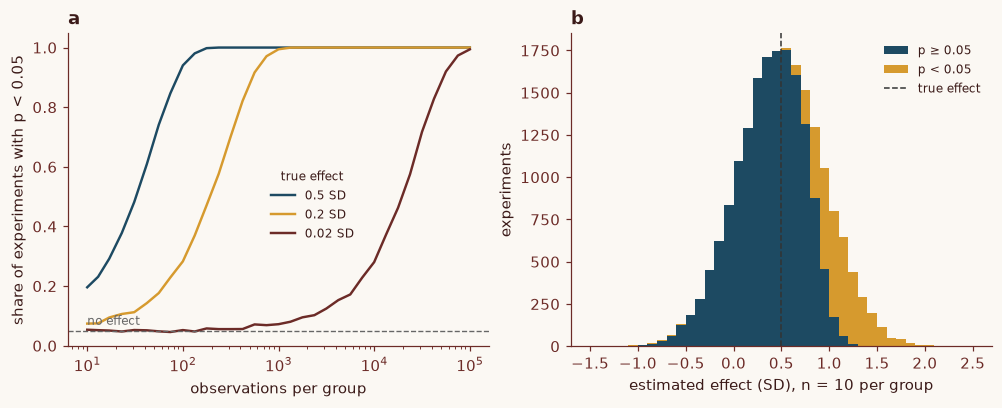

In [6]:
ns = np.unique(np.logspace(1, 5, 33).astype(int))
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
for delta, c in zip((0.5, 0.2, 0.02), C):
    power = [np.mean(experiments(delta, n, 4000)[0] < ALPHA) for n in ns]
    a.plot(ns, power, color=c, lw=1.6, label=f"{delta} SD")
a.axhline(ALPHA, color="0.4", lw=0.9, ls="--")
a.text(ns[0], ALPHA + 0.02, "no effect", color="0.4", fontsize=8)
a.set_xscale("log")
a.set_xlabel("observations per group")
a.set_ylabel("share of experiments with p < 0.05")
a.legend(
    frameon=False,
    fontsize=8,
    title="true effect",
    title_fontsize=8,
    loc="center",
    bbox_to_anchor=(0.58, 0.45),
)
a.set_title("a", loc="left", fontweight="bold")

bins = np.linspace(-1.5, 2.5, 41)
b.hist(
    [est_big[~sig_big], est_big[sig_big]],
    bins=bins,
    stacked=True,
    color=C[:2],
    label=["p ≥ 0.05", "p < 0.05"],
)
b.axvline(0.5, color="0.2", lw=1.0, ls="--", label="true effect")
b.set_xlabel("estimated effect (SD), n = 10 per group")
b.set_ylabel("experiments")
b.legend(frameon=False, fontsize=8, loc="upper right")
b.set_title("b", loc="left", fontweight="bold")
plt.show()

<strong>Figure 2 | Significance tracks sample size as much as effect size, and a significant small study overstates its effect.</strong> <strong>a</strong>, Share of 4,000 simulated experiments with p < 0.05 against observations per group, for true effects of 0.5, 0.2 and 0.02 standard deviations; dashed, the 5% reached with no effect. Given enough data any non-zero effect becomes significant. <strong>b</strong>, Estimated effects from the 20,000 experiments with a true effect of 0.5 (dashed) and 10 per group, stacked by whether p < 0.05. Of the significant ones, 99.1% overestimated the effect and the other 0.9% got its sign wrong.

What a reader needs instead is the estimate, an interval showing how precisely it was measured, and a judgement about whether an effect that size would matter.

## Many tests make false findings

A threshold of 0.05 promises a 5% false-positive rate *per test*. Run $k$ tests on data with no effects and the chance that at least one comes out significant is

$$1 - (1 - \alpha)^k$$

where $\alpha = 0.05$ is the threshold and $k$ is the number of independent tests. We check this by simulating 5,000 studies, each running 50 tests on pure noise, and recording how often at least one of the first $k$ tests is significant.

In [7]:
STUDIES, K = 5_000, 50
p, _ = experiments(0.0, 20, STUDIES * K)
p = p.reshape(STUDIES, K)
k = np.arange(1, K + 1)
at_least_one = (np.minimum.accumulate(p, axis=1) < ALPHA).mean(axis=0)
for kk in (1, 5, 20, 50):
    print(
        f"{kk:>2} independent tests, no effects: {at_least_one[kk - 1]:.3f} of studies find p < 0.05 "
        f"(1 - 0.95^{kk} = {1 - (1 - ALPHA) ** kk:.2f})"
    )
print(
    f"largest gap from the formula over k = 1..{K}: {np.abs(at_least_one - (1 - (1 - ALPHA) ** k)).max():.3f}"
)

 1 independent tests, no effects: 0.055 of studies find p < 0.05 (1 - 0.95^1 = 0.05)
 5 independent tests, no effects: 0.224 of studies find p < 0.05 (1 - 0.95^5 = 0.23)
20 independent tests, no effects: 0.642 of studies find p < 0.05 (1 - 0.95^20 = 0.64)
50 independent tests, no effects: 0.921 of studies find p < 0.05 (1 - 0.95^50 = 0.92)
largest gap from the formula over k = 1..50: 0.008


One test gives a significant result in 5.5% of studies, the expected 5% plus simulation noise; five tests in 22%; twenty in 64%; fifty in 92%. The simulation matches the formula to within 0.008 at every $k$ from 1 to 50. A study that measures twenty outcomes and reports the one that worked will usually have something to report, with nothing there.

The tests need not be counted to do the damage. An analyst with one dataset chooses which outcome, which subgroup, whether to drop outliers. Each choice is defensible and each is a different test, the "garden of forking paths", a phrase from Gelman and Loken[^3]. Below, a dataset of 100 people with no treatment effect is analysed every reasonable way: three outcomes (two measures correlated at 0.5, and their average), three samples (everyone, men, women), with and without outliers beyond two standard deviations.

In [8]:
def forking_paths(n=100):
    """One null dataset, analysed every reasonable way. Returns the smallest p."""
    treated = rng.random(n) < 0.5
    sex = rng.random(n) < 0.5
    y1 = rng.normal(size=n)
    y2 = 0.5 * y1 + np.sqrt(1 - 0.5**2) * rng.normal(size=n)  # correlation 0.5
    smallest = 1.0
    for y in (y1, y2, (y1 + y2) / 2):  # outcome 1, outcome 2, their average
        for keep in (np.ones(n, bool), sex, ~sex):  # everyone, men, women
            for use in (keep, keep & (np.abs(y) < 2)):  # with and without outliers
                smallest = min(
                    smallest,
                    stats.ttest_ind(y[use & treated], y[use & ~treated]).pvalue,
                )
    return smallest


PATHS = 3 * 3 * 2
min_p = np.array([forking_paths() for _ in range(2_000)])
print(
    f"{PATHS} analyses of one dataset with no effect: {np.mean(min_p < ALPHA):.2f} of datasets give p < 0.05 "
    f"on at least one (independent tests would give {1 - (1 - ALPHA) ** PATHS:.2f})"
)

18 analyses of one dataset with no effect: 0.29 of datasets give p < 0.05 on at least one (independent tests would give 0.60)


With 18 analyses available, 29% of datasets with no effect give at least one p < 0.05. The paths overlap, so this is less than the 60% from 18 independent tests, but still nearly six times the advertised 5%. The analyst need not be dishonest: knowing the data makes some choices look more natural. This is why "the model" in the definition includes a test fixed before the data are seen. If the analysis followed the data, the p-value no longer means what it says.

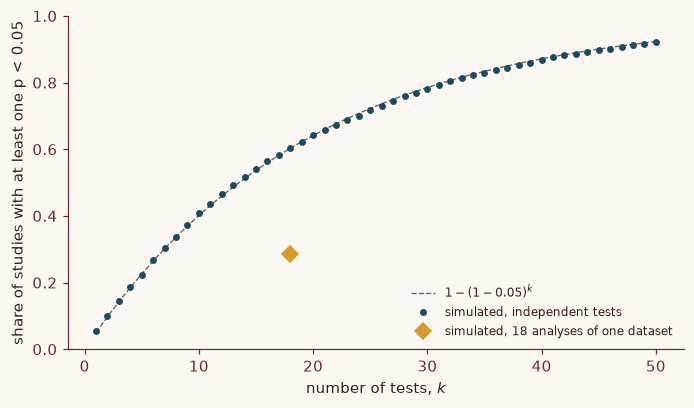

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 3.6), layout="constrained")
ax.plot(k, 1 - (1 - ALPHA) ** k, color="0.4", lw=0.9, ls="--", label="$1-(1-0.05)^k$")
ax.plot(k, at_least_one, "o", ms=3.5, color=C[0], label="simulated, independent tests")
ax.plot(
    PATHS,
    np.mean(min_p < ALPHA),
    "D",
    ms=7,
    color=C[1],
    label=f"simulated, {PATHS} analyses of one dataset",
)
ax.set_xlabel("number of tests, $k$")
ax.set_ylabel("share of studies with at least one p < 0.05")
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.show()

<strong>Figure 3 | The more tests, the more certain a false finding becomes.</strong> Share of 5,000 simulated studies with no true effects in which at least one of the first $k$ tests gives p < 0.05 (circles), against $1-(1-0.05)^k$ (dashed). Diamond, the same share for 18 overlapping analyses of each of 2,000 null datasets.

The cookbook audit in [Reading a nutrition study](../reading-a-nutrition-study.qmd), where 40 of 50 common ingredients had a published association with cancer[^4], is consistent with this at the scale of a literature: many foods, cancers, cohorts and analysis choices, filtered through journals that print the significant ones. The defences follow. Fix the analysis in public before seeing the data (pre-registration). Report every test, not only the ones that worked. When many tests are unavoidable, tighten the threshold; the simplest way, the Bonferroni correction, divides $\alpha$ by $k$.

## Key takeaways

- A p-value is the probability of data at least as extreme as yours if the null hypothesis and every model assumption hold. It describes the data under an assumption, not the assumption.
- With no effect, p-values are uniform between 0 and 1. A threshold of 0.05 is the false-positive rate for one test of a true null, nothing more.
- A p-value is not the probability that the null is true. That depends on how often the hypotheses tested are real, which the p-value does not know.
- A p-value is not an effect size. Large samples make trivial effects significant; small samples miss large ones, and the significant ones they do find are overestimates.
- p > 0.05 is not evidence of no effect; it often means the study was too small to tell.
- Many tests, or many ways of analysing one dataset, manufacture significant results. Ask how many tests were run and whether the analysis was fixed in advance.

## References

[^1]: Wasserstein, R. L. & Lazar, N. A. The ASA statement on p-values: context, process, and purpose. *Am. Stat.* **70**, 129–133 (2016). https://doi.org/10.1080/00031305.2016.1154108
[^2]: Greenland, S. et al. Statistical tests, P values, confidence intervals, and power: a guide to misinterpretations. *Eur. J. Epidemiol.* **31**, 337–350 (2016). https://doi.org/10.1007/s10654-016-0149-3
[^3]: Gelman, A. & Loken, E. The statistical crisis in science. *Am. Sci.* **102**, 460–465 (2014). https://doi.org/10.1511/2014.111.460
[^4]: Schoenfeld, J. D. & Ioannidis, J. P. A. Is everything we eat associated with cancer? A systematic cookbook review. *Am. J. Clin. Nutr.* **97**, 127–134 (2013). https://doi.org/10.3945/ajcn.112.047142

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/least-squares.html"><span>Previous</span>Least squares</a><a class="mf-up" href="/series/statistics/index.html"><span>Series</span>Statistics</a></div>
<!-- CURRICULUM_FOOTER_END -->